# AI Interview-Preparation Agent with Groq + NLP Analytics

**BDSMA Extra Experiment — Option III.13**

## Aim
Build a Colab-based interview-preparation agent that analyzes a software-engineering interview question dataset, generates role-focused questions, conducts a short mock interview, evaluates answers, identifies weak topics, and creates revision exercises.

## Dataset
Upload **`Software Questions.csv`**. The dataset description says it contains approximately 250 software-engineering interview questions and these fields (column names may vary slightly):

- `Question Number`
- `Question`
- `Brief Answer` or `Answer`
- `Category`
- `Difficulty`

The notebook automatically maps common column-name variations. It also works with a CSV that only has `Question` and `Answer`; missing categories/difficulty are filled with `Uncategorized`/`Unknown`.

## What this notebook demonstrates
1. Dataset cleaning and quality checks.
2. Category/difficulty distribution and keyword-frequency analysis.
3. Groq-powered generation of questions based on a target job.
4. A conversational, multi-question mock interview.
5. AI evaluation of technical accuracy, completeness, and communication clarity.
6. Topic-wise performance analysis, weak-area identification, and revision exercises.

**Note:** The scoring is an AI-assisted practice estimate, not a formal hiring assessment. Scores can vary between runs. The dataset's `Brief Answer` is used as a reference, not as the only possible correct answer.

## 1. Imports and Groq API setup

Add a secret named **`GROQ_API_KEY`** in Colab's Secrets (key icon on the left) and allow this notebook to access it. The key is read from Secrets; it is never printed.

In [1]:

import os
import re
import json
import random
import textwrap
import warnings
from collections import Counter
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from IPython.display import display, Markdown
from dotenv import load_dotenv
from groq import Groq

warnings.filterwarnings("ignore", category=FutureWarning)

# Load environment variables from the project's .env file
load_dotenv(Path.cwd() / ".env")

GROQ_API_KEY = os.getenv("GROQ_API_KEY")

if not GROQ_API_KEY:
    raise RuntimeError(
        "GROQ_API_KEY was not found. Create a .env file in your project "
        "folder and add GROQ_API_KEY=your_actual_api_key."
    )

client = Groq(api_key=GROQ_API_KEY)

# Select a model available to your Groq account
MODEL_CANDIDATES = [
    "openai/gpt-oss-20b",
    "openai/gpt-oss-120b",
    "qwen/qwen3.8-27b",
]

try:
    available_model_ids = {
        model.id for model in client.models.list().data
    }

    MODEL = next(
        (m for m in MODEL_CANDIDATES if m in available_model_ids),
        None
    )

    if MODEL is None:
        raise RuntimeError(
            "None of the preferred models is available. "
            "Check the model IDs enabled for your Groq account."
        )

    print("Groq connection configured.")
    print("Selected model:", MODEL)

except Exception as exc:
    raise RuntimeError(
        "Could not verify Groq models. Check your API key, internet "
        "connection, and the models available to your account. "
        f"Details: {exc}"
    ) from exc


def groq_chat(messages, temperature=0.2, max_completion_tokens=1200):
    """Send a chat-completion request to Groq."""
    response = client.chat.completions.create(
        model=MODEL,
        messages=messages,
        temperature=temperature,
        max_completion_tokens=max_completion_tokens,
    )
    return response.choices[0].message.content or ""


def parse_json_response(raw_text):
    """Parse JSON, including responses wrapped in Markdown fences."""
    cleaned = raw_text.strip()
    cleaned = re.sub(
        r"^```(?:json)?\s*", "", cleaned, flags=re.IGNORECASE
    )
    cleaned = re.sub(r"\s*```$", "", cleaned)

    try:
        return json.loads(cleaned)
    except json.JSONDecodeError:
        first_object = cleaned.find("{")
        first_array = cleaned.find("[")

        if first_array != -1 and (
            first_object == -1 or first_array < first_object
        ):
            end = cleaned.rfind("]")
            candidate = (
                cleaned[first_array:end + 1]
                if end > first_array else ""
            )
        elif first_object != -1:
            end = cleaned.rfind("}")
            candidate = (
                cleaned[first_object:end + 1]
                if end > first_object else ""
            )
        else:
            candidate = ""

        if not candidate:
            raise ValueError(
                "The model did not return valid JSON. Please retry."
            )

        return json.loads(candidate)


print("Setup complete. The API key was loaded without displaying it.")

Groq connection configured.
Selected model: openai/gpt-oss-20b
Setup complete. The API key was loaded without displaying it.


In [2]:
reply = groq_chat([
    {
        "role": "user",
        "content": "Reply with exactly: Interview agent is ready."
    }
])

print(reply)

Interview agent is ready.


## 2. Upload and inspect the software interview dataset

Run the cell and upload `Software Questions.csv` from your device. If multiple CSV files are uploaded, the notebook prefers a filename containing `software`.

In [3]:

from pathlib import Path
import pandas as pd

CSV_PATH = Path("Software Questions.csv")

if not CSV_PATH.exists():
    raise FileNotFoundError(
        f"Cannot find {CSV_PATH.resolve()}. "
        "Place the CSV in your VS Code project folder."
    )

# Try common encodings used by CSV files on Windows
encodings = ["utf-8-sig", "cp1252", "latin1"]
df_raw = None
used_encoding = None

for encoding in encodings:
    try:
        df_raw = pd.read_csv(CSV_PATH, encoding=encoding)
        used_encoding = encoding
        break
    except UnicodeDecodeError:
        continue

if df_raw is None:
    raise ValueError("Could not read the CSV using the supported encodings.")

print(f"Loaded file: {CSV_PATH}")
print(f"Encoding used: {used_encoding}")
print(f"Rows: {len(df_raw):,} | Columns: {len(df_raw.columns)}")
print("Original columns:", list(df_raw.columns))

display(df_raw.head(8))


Loaded file: Software Questions.csv
Encoding used: cp1252
Rows: 200 | Columns: 5
Original columns: ['Question Number', 'Question', 'Answer', 'Category', 'Difficulty']


,Question Number,Question,Answer,Category,Difficulty
0,1,What is the difference between compilation and...,Compilation translates source code into machin...,General Programming,Medium
1,2,Explain the concept of polymorphism.,Polymorphism allows objects of different class...,General Programming,Medium
2,3,Define encapsulation and give an example.,Encapsulation bundles data and methods in a cl...,General Programming,Hard
3,4,"What is an abstract class, and how is it diffe...",An abstract class can't be instantiated and ca...,General Programming,Medium
4,5,Describe the principles of Object-Oriented Pro...,"OOP principles include encapsulation, inherita...",General Programming,Medium
5,6,What is the purpose of a constructor?,A constructor initializes object properties up...,General Programming,Medium
6,7,Explain the difference between stack and heap ...,Stack memory stores local variables and functi...,General Programming,Medium
7,8,"What is a design pattern, and can you name a few?",Design patterns are solutions to common design...,General Programming,Medium


## 3. Clean and standardize the columns

The following cell handles common variants such as `Brief Answer`, `Answer`, `Question Text`, and `Topic`. It removes rows without a usable question and keeps a standardized copy for the rest of the notebook.

In [4]:

import os
import re
import json
import random
import textwrap
import warnings
from collections import Counter
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from IPython.display import display, Markdown
from dotenv import load_dotenv
from groq import Groq

warnings.filterwarnings("ignore", category=FutureWarning)

# Load environment variables from the project's .env file
load_dotenv(Path.cwd() / ".env")

GROQ_API_KEY = os.getenv("GROQ_API_KEY")

if not GROQ_API_KEY:
    raise RuntimeError(
        "GROQ_API_KEY was not found. Create a .env file in your project "
        "folder and add GROQ_API_KEY=your_actual_api_key."
    )

client = Groq(api_key=GROQ_API_KEY)

# Select a model available to your Groq account
MODEL_CANDIDATES = [
    "openai/gpt-oss-20b",
    "openai/gpt-oss-120b",
    "qwen/qwen3.8-27b",
]

try:
    available_model_ids = {
        model.id for model in client.models.list().data
    }

    MODEL = next(
        (m for m in MODEL_CANDIDATES if m in available_model_ids),
        None
    )

    if MODEL is None:
        raise RuntimeError(
            "None of the preferred models is available. "
            "Check the model IDs enabled for your Groq account."
        )

    print("Groq connection configured.")
    print("Selected model:", MODEL)

except Exception as exc:
    raise RuntimeError(
        "Could not verify Groq models. Check your API key, internet "
        "connection, and the models available to your account. "
        f"Details: {exc}"
    ) from exc


def groq_chat(messages, temperature=0.2, max_completion_tokens=1200):
    """Send a chat-completion request to Groq."""
    response = client.chat.completions.create(
        model=MODEL,
        messages=messages,
        temperature=temperature,
        max_completion_tokens=max_completion_tokens,
    )
    return response.choices[0].message.content or ""


def parse_json_response(raw_text):
    """Parse JSON, including responses wrapped in Markdown fences."""
    cleaned = raw_text.strip()
    cleaned = re.sub(
        r"^```(?:json)?\s*", "", cleaned, flags=re.IGNORECASE
    )
    cleaned = re.sub(r"\s*```$", "", cleaned)

    try:
        return json.loads(cleaned)
    except json.JSONDecodeError:
        first_object = cleaned.find("{")
        first_array = cleaned.find("[")

        if first_array != -1 and (
            first_object == -1 or first_array < first_object
        ):
            end = cleaned.rfind("]")
            candidate = (
                cleaned[first_array:end + 1]
                if end > first_array else ""
            )
        elif first_object != -1:
            end = cleaned.rfind("}")
            candidate = (
                cleaned[first_object:end + 1]
                if end > first_object else ""
            )
        else:
            candidate = ""

        if not candidate:
            raise ValueError(
                "The model did not return valid JSON. Please retry."
            )

        return json.loads(candidate)


print("Setup complete. The API key was loaded without displaying it.")

Groq connection configured.
Selected model: openai/gpt-oss-20b
Setup complete. The API key was loaded without displaying it.


In [5]:
def normalize_column_name(name):
    return re.sub(r"[^a-z0-9]", "", str(name).strip().lower())

normalized_to_original = {normalize_column_name(c): c for c in df_raw.columns}


def find_column(candidates, required=False):
    for candidate in candidates:
        key = normalize_column_name(candidate)
        if key in normalized_to_original:
            return normalized_to_original[key]
    if required:
        raise ValueError(
            f"Could not find a required column from {candidates}. "
            f"Available columns: {list(df_raw.columns)}"
        )
    return None

q_col = find_column(["Question", "Interview Question", "Question Text", "Questions"], required=True)
a_col = find_column(["Brief Answer", "Answer", "Reference Answer", "Answer Text", "Expected Answer"])
cat_col = find_column(["Category", "Topic", "Subject", "Domain"])
diff_col = find_column(["Difficulty", "Difficulty Level", "Level"])
id_col = find_column(["Question Number", "Question No", "ID", "Index"])

rename_map = {q_col: "Question"}
if a_col: rename_map[a_col] = "Answer"
if cat_col: rename_map[cat_col] = "Category"
if diff_col: rename_map[diff_col] = "Difficulty"
if id_col: rename_map[id_col] = "QuestionNumber"

df = df_raw.rename(columns=rename_map).copy()
if "Answer" not in df.columns:
    df["Answer"] = "No reference answer supplied in the dataset."
if "Category" not in df.columns:
    df["Category"] = "Uncategorized"
if "Difficulty" not in df.columns:
    df["Difficulty"] = "Unknown"
if "QuestionNumber" not in df.columns:
    df["QuestionNumber"] = range(1, len(df) + 1)

for col in ["Question", "Answer", "Category", "Difficulty"]:
    df[col] = df[col].fillna("").astype(str).str.strip()

df["Question"] = df["Question"].str.replace(r"\s+", " ", regex=True)
df["Answer"] = df["Answer"].str.replace(r"\s+", " ", regex=True)
df["Category"] = df["Category"].replace("", "Uncategorized")
df["Difficulty"] = df["Difficulty"].replace("", "Unknown").str.title()

before_rows = len(df)
df = df[df["Question"].ne("")].copy()
removed_missing_questions = before_rows - len(df)
df["_question_key"] = df["Question"].str.lower().str.replace(r"[^a-z0-9]+", " ", regex=True).str.strip()
duplicates_removed = int(df["_question_key"].duplicated().sum())
df = df.drop_duplicates("_question_key").drop(columns="_question_key").reset_index(drop=True)

print(f"Rows after cleaning: {len(df):,}")
print(f"Rows removed because question was missing: {removed_missing_questions}")
print(f"Duplicate questions removed: {duplicates_removed}")
print(f"Distinct categories: {df['Category'].nunique()}")
print("\nCategory values:")
print(sorted(df["Category"].unique().tolist()))
display(df[["QuestionNumber", "Question", "Answer", "Category", "Difficulty"]].head(10))

Rows after cleaning: 174
Rows removed because question was missing: 0
Duplicate questions removed: 26
Distinct categories: 22

Category values:
['Algorithms', 'Artificial Intelligence', 'Back-end', 'Data Engineering', 'Data Structures', 'Database Systems', 'Database and SQL', 'DevOps', 'Distributed Systems', 'Front-end', 'Full-stack', 'General Program', 'General Programming', 'Languages and Frameworks', 'Low-level Systems', 'Machine Learning', 'Networking', 'Security', 'Software Testing', 'System Design', 'Version Control', 'Web Development']


,QuestionNumber,Question,Answer,Category,Difficulty
0,1,What is the difference between compilation and...,Compilation translates source code into machin...,General Programming,Medium
1,2,Explain the concept of polymorphism.,Polymorphism allows objects of different class...,General Programming,Medium
2,3,Define encapsulation and give an example.,Encapsulation bundles data and methods in a cl...,General Programming,Hard
3,4,"What is an abstract class, and how is it diffe...",An abstract class can't be instantiated and ca...,General Programming,Medium
4,5,Describe the principles of Object-Oriented Pro...,"OOP principles include encapsulation, inherita...",General Programming,Medium
5,6,What is the purpose of a constructor?,A constructor initializes object properties up...,General Programming,Medium
6,7,Explain the difference between stack and heap ...,Stack memory stores local variables and functi...,General Programming,Medium
7,8,"What is a design pattern, and can you name a few?",Design patterns are solutions to common design...,General Programming,Medium
8,9,"Define the term ""DRY"" in software development.",DRY (Don't Repeat Yourself) advocates for avoi...,General Programming,Medium
9,10,What is the SOLID principle?,SOLID represents five design principles for OO...,General Program,Hard


## 4. Exploratory data analysis

These charts summarize the data available in the uploaded CSV. They describe the dataset; they do not prove that a category is trending over time, because the file does not contain dates.

DATASET SUMMARY
---------------------------------------------
Questions: 174
Categories: 22
Difficulty labels: 3
Questions missing an answer: 0
Median question length: 9 words


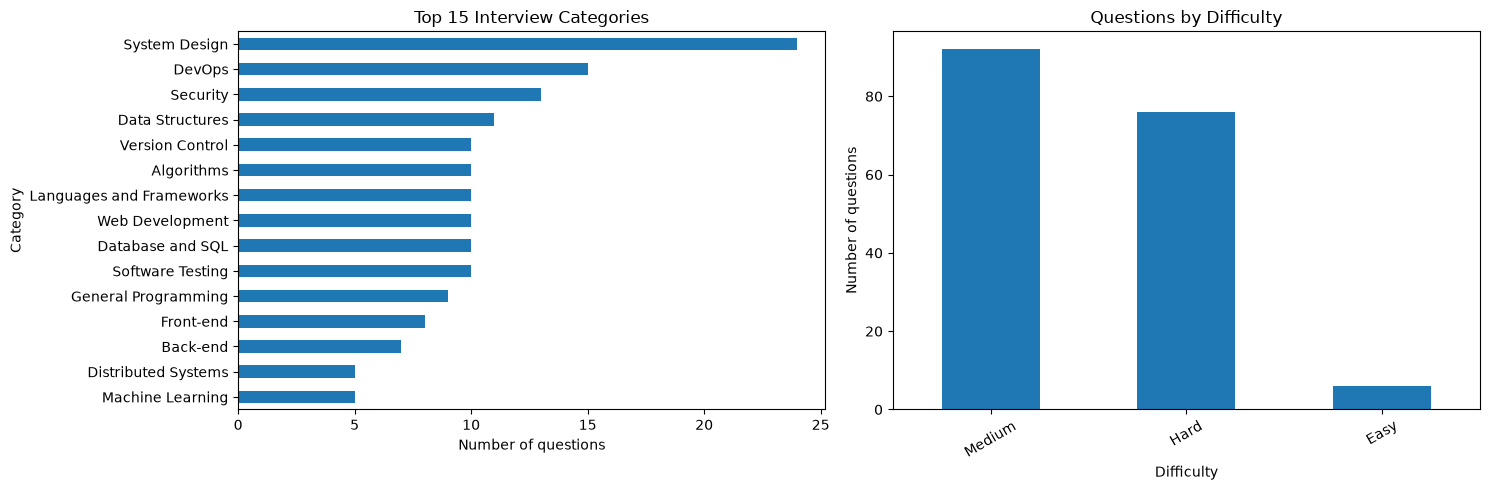

,Category,Questions,Average_Question_Words,Difficulties
0,System Design,24,8.8,"Easy, Hard, Medium"
1,DevOps,15,9.4,"Easy, Hard, Medium"
2,Security,13,8.5,"Hard, Medium"
3,Data Structures,11,8.4,"Easy, Hard, Medium"
4,Database and SQL,10,9.0,"Easy, Hard, Medium"
5,Algorithms,10,10.0,Hard
6,Version Control,10,9.4,"Hard, Medium"
7,Software Testing,10,7.8,"Easy, Hard, Medium"
8,Languages and Frameworks,10,7.2,"Hard, Medium"
9,Web Development,10,8.0,"Hard, Medium"


In [6]:
print("DATASET SUMMARY")
print("-" * 45)
print(f"Questions: {len(df):,}")
print(f"Categories: {df['Category'].nunique():,}")
print(f"Difficulty labels: {df['Difficulty'].nunique():,}")
print(f"Questions missing an answer: {(df['Answer'].str.strip() == '').sum():,}")
print(f"Median question length: {df['Question'].str.split().str.len().median():.0f} words")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
category_counts = df["Category"].value_counts().head(15).sort_values()
category_counts.plot(kind="barh", ax=axes[0])
axes[0].set_title("Top 15 Interview Categories")
axes[0].set_xlabel("Number of questions")
axes[0].set_ylabel("Category")

difficulty_counts = df["Difficulty"].value_counts()
difficulty_counts.plot(kind="bar", ax=axes[1])
axes[1].set_title("Questions by Difficulty")
axes[1].set_xlabel("Difficulty")
axes[1].set_ylabel("Number of questions")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

display(df.groupby("Category").agg(
    Questions=("Question", "count"),
    Average_Question_Words=("Question", lambda s: round(s.str.split().str.len().mean(), 1)),
    Difficulties=("Difficulty", lambda s: ", ".join(sorted(set(s))))
).sort_values("Questions", ascending=False).reset_index())

## 5. Keyword frequency analysis with NLP

CountVectorizer converts the questions into token counts after basic stop-word removal. This is a simple, explainable baseline for finding common terms.

,Keyword / phrase,Frequency
0,explain,30
1,design,23
2,web,13
3,implement,13
4,algorithm,11
5,difference,11
6,concept,11
7,distributed,10
8,explain concept,10
9,discuss,9


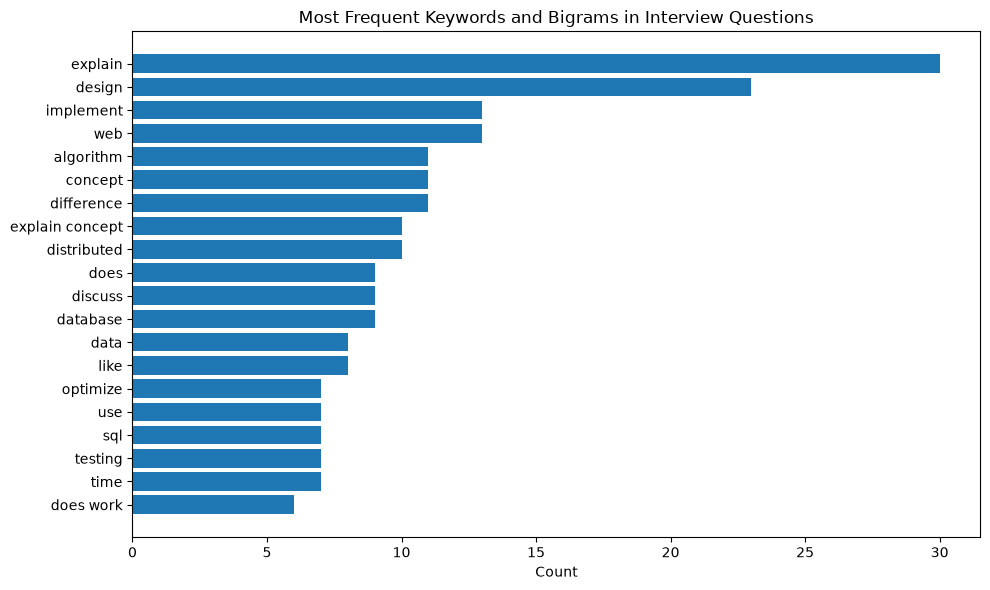

In [7]:
question_texts = df["Question"].astype(str).tolist()
vectorizer = CountVectorizer(stop_words="english", ngram_range=(1, 2), max_features=30)
try:
    matrix = vectorizer.fit_transform(question_texts)
    keyword_counts = matrix.sum(axis=0).A1
    keyword_df = pd.DataFrame({"Keyword / phrase": vectorizer.get_feature_names_out(), "Frequency": keyword_counts})
    keyword_df = keyword_df.sort_values("Frequency", ascending=False).head(20).sort_values("Frequency")
    display(keyword_df.sort_values("Frequency", ascending=False).reset_index(drop=True))
    plt.figure(figsize=(10, 6))
    plt.barh(keyword_df["Keyword / phrase"], keyword_df["Frequency"])
    plt.title("Most Frequent Keywords and Bigrams in Interview Questions")
    plt.xlabel("Count")
    plt.tight_layout()
    plt.show()
except ValueError as exc:
    print("Could not compute keyword frequencies. Check that the Question column contains enough text.", exc)

## 6. Choose a target role and generate tailored interview questions

The system uses both sources:
- **Dataset questions** supply real question/answer examples from the uploaded CSV.
- **Groq-generated questions** add new questions tailored to the target role.

The role-category filter is a lightweight heuristic. If it cannot find a suitable category, the notebook falls back to the full dataset.

In [8]:
ROLE_CATEGORY_HINTS = {
    "ai engineer": ["machine learning", "artificial intelligence", "data engineering", "system design", "database", "security", "devops", "data structures"],
    "machine learning engineer": ["machine learning", "artificial intelligence", "data engineering", "system design", "data structures", "database"],
    "data scientist": ["machine learning", "artificial intelligence", "data engineering", "database", "data structures", "statistics"],
    "data engineer": ["data engineering", "database", "distributed systems", "system design", "devops", "networking"],
    "software engineer": ["general programming", "data structures", "algorithms", "languages and frameworks", "system design", "software testing", "version control", "database", "devops"],
    "backend engineer": ["system design", "database", "security", "networking", "languages and frameworks", "devops", "data structures"],
    "devops engineer": ["devops", "system design", "cloud", "networking", "security", "software testing"],
}


def get_role_pool(role, difficulty="Any", focus_topics=""):
    role_key = role.strip().lower()
    hints = ROLE_CATEGORY_HINTS.get(role_key, [])
    if hints:
        role_mask = df["Category"].str.lower().apply(lambda c: any(hint in c for hint in hints))
        role_pool = df[role_mask].copy()
    else:
        role_pool = df.copy()
    if role_pool.empty:
        role_pool = df.copy()

    # If the student enters focus topics (e.g. Python, NLP, RAG, APIs), try to
    # find dataset rows mentioning them in the question, answer, or category.
    # If there are no matches, keep the role pool and let Groq supply new questions.
    requested_topics = [part.strip().lower() for part in str(focus_topics).split(",") if part.strip()]
    if requested_topics:
        searchable_text = (
            role_pool["Question"].fillna("") + " " +
            role_pool["Answer"].fillna("") + " " +
            role_pool["Category"].fillna("")
        ).str.lower()
        topic_mask = searchable_text.apply(lambda text: any(topic in text for topic in requested_topics))
        focused_pool = role_pool[topic_mask].copy()
        if not focused_pool.empty:
            role_pool = focused_pool

    if difficulty and difficulty.lower() != "any":
        difficulty_pool = role_pool[role_pool["Difficulty"].str.lower() == difficulty.lower()]
        if not difficulty_pool.empty:
            role_pool = difficulty_pool
    return role_pool


def generate_role_questions(target_role, focus_topics, n_questions, dataset_examples):
    """Generate new question/reference-answer pairs tailored to a job role."""
    if n_questions <= 0:
        return []
    examples = [
        {"category": str(row["Category"]), "difficulty": str(row["Difficulty"]),
         "question": str(row["Question"]), "reference_answer": str(row["Answer"])[:700]}
        for _, row in dataset_examples.head(8).iterrows()
    ]
    prompt = f"""Create exactly {n_questions} original technical interview question(s) for the target role: {target_role}.
Focus topics: {focus_topics or 'Choose the most relevant topics for this role.'}
Use the supplied dataset examples to understand the dataset's style and coverage, but do not copy their questions verbatim.
For every question, provide a concise, technically sound reference answer and a category and difficulty.
Return ONLY valid JSON as an array of objects with these keys: question, reference_answer, category, difficulty.
Difficulty must be Easy, Medium, or Hard. Avoid duplicate questions. Do not add Markdown fences.

Dataset examples:
{json.dumps(examples, ensure_ascii=False)}"""
    raw = groq_chat([
        {"role": "system", "content": "You are a technical interviewer and careful answer-key writer. Produce accurate, concise interview material."},
        {"role": "user", "content": prompt},
    ], temperature=0.35, max_completion_tokens=1800)
    data = parse_json_response(raw)
    if isinstance(data, dict):
        data = data.get("questions", data.get("items", []))
    if not isinstance(data, list):
        raise ValueError("Expected the generated question response to be a JSON array.")
    cleaned = []
    for item in data:
        if isinstance(item, dict) and item.get("question") and item.get("reference_answer"):
            cleaned.append({
                "Question": str(item["question"]).strip(),
                "Answer": str(item["reference_answer"]).strip(),
                "Category": str(item.get("category", "Role-specific" )).strip(),
                "Difficulty": str(item.get("difficulty", "Medium")).title(),
                "Source": "Groq-generated",
            })
    return cleaned[:n_questions]

print("Available categories:", ", ".join(sorted(df["Category"].unique())))
print("Example role options: AI Engineer, Machine Learning Engineer, Data Scientist, Data Engineer, Software Engineer, Backend Engineer, DevOps Engineer")

Available categories: Algorithms, Artificial Intelligence, Back-end, Data Engineering, Data Structures, Database Systems, Database and SQL, DevOps, Distributed Systems, Front-end, Full-stack, General Program, General Programming, Languages and Frameworks, Low-level Systems, Machine Learning, Networking, Security, Software Testing, System Design, Version Control, Web Development
Example role options: AI Engineer, Machine Learning Engineer, Data Scientist, Data Engineer, Software Engineer, Backend Engineer, DevOps Engineer


In [19]:
import random
import pandas as pd


def build_interview_bank(
    target_role,
    focus_topics="",
    count=5,
    difficulty="Any"
):
    """
    Build an interview question bank using dataset questions
    and AI-generated questions.
    """

    count = max(1, min(10, int(count)))

    # Step 1: Get questions matching the role, difficulty,
    # and requested focus topics.
    pool = get_role_pool(
        target_role,
        difficulty,
        focus_topics
    )

    if pool is None:
        pool = pd.DataFrame()

    pool = pool.copy()

    # Step 2: Select approximately 60% of questions from the dataset.
    dataset_count = min(
        len(pool),
        max(1, round(count * 0.6))
    )

    if dataset_count > 0:
        dataset_questions = pool.sample(
            n=dataset_count,
            random_state=42
        ).copy()
    else:
        dataset_questions = pd.DataFrame(
            columns=["Question", "Answer", "Category", "Difficulty"]
        )

    dataset_questions["Source"] = "Dataset"

    # Step 3: Generate the remaining questions using the AI function.
    questions_needed = count - len(dataset_questions)

    generated_questions = pd.DataFrame()

    if questions_needed > 0:
        # Supply relevant examples to guide question generation.
        if not pool.empty:
            dataset_examples = pool.sample(
                n=min(5, len(pool)),
                random_state=42
            )
        elif "df" in globals() and not df.empty:
            dataset_examples = df.head(5).copy()
        else:
            dataset_examples = pd.DataFrame()

        generated = generate_role_questions(
            target_role,
            focus_topics,
            questions_needed,
            dataset_examples
        )

        if isinstance(generated, pd.DataFrame):
            generated_questions = generated.copy()
        elif isinstance(generated, list):
            generated_questions = pd.DataFrame(generated)

        # Normalize common column-name variations.
        aliases = {
            "question": "Question",
            "answer": "Answer",
            "reference_answer": "Answer",
            "category": "Category",
            "difficulty": "Difficulty",
            "source": "Source"
        }

        rename_columns = {}

        for column in generated_questions.columns:
            normalized_name = str(column).strip().lower()

            if normalized_name in aliases:
                rename_columns[column] = aliases[normalized_name]

        generated_questions = generated_questions.rename(
            columns=rename_columns
        )

        # Ensure all expected columns exist.
        for column in [
            "Question",
            "Answer",
            "Category",
            "Difficulty"
        ]:
            if column not in generated_questions.columns:
                generated_questions[column] = ""

        if "Source" not in generated_questions.columns:
            generated_questions["Source"] = "AI-generated"
        else:
            generated_questions["Source"] = (
                generated_questions["Source"]
                .fillna("AI-generated")
            )

    # Step 4: Combine dataset and AI-generated questions.
    bank = pd.concat(
        [dataset_questions, generated_questions],
        ignore_index=True
    )

    # Step 5: Remove empty questions and duplicates.
    bank["Question"] = bank["Question"].fillna("").astype(str)
    bank["Answer"] = bank["Answer"].fillna("").astype(str)

    bank = bank[
        bank["Question"].str.strip() != ""
    ].copy()

    bank["_question_key"] = (
        bank["Question"].str.strip().str.casefold()
    )

    bank = bank.drop_duplicates(
        subset="_question_key",
        keep="first"
    ).drop(columns="_question_key")

    # Step 6: If generation returned too few questions,
    # add unused questions from the dataset where possible.
    if len(bank) < count and not pool.empty:
        used_questions = set(
            bank["Question"].str.strip().str.casefold()
        )

        remaining_pool = pool.copy()
        remaining_pool["Question"] = (
            remaining_pool["Question"].fillna("").astype(str)
        )

        remaining_pool = remaining_pool[
            ~remaining_pool["Question"]
            .str.strip()
            .str.casefold()
            .isin(used_questions)
        ]

        if not remaining_pool.empty:
            extra_count = min(
                count - len(bank),
                len(remaining_pool)
            )

            extra_questions = remaining_pool.sample(
                n=extra_count,
                random_state=43
            ).copy()

            extra_questions["Source"] = "Dataset"

            bank = pd.concat(
                [bank, extra_questions],
                ignore_index=True
            )

    # Step 7: Shuffle and return the final question bank.
    bank = bank.sample(
        frac=1,
        random_state=random.randint(0, 100000)
    ).reset_index(drop=True)

    expected_columns = [
        "Question",
        "Answer",
        "Category",
        "Difficulty",
        "Source"
    ]

    for column in expected_columns:
        if column not in bank.columns:
            bank[column] = ""

    bank = bank[expected_columns]

    print(
        f"Question bank ready: {len(bank)} questions "
        f"for {target_role}."
    )

    return bank.to_dict(orient="records")


print("build_interview_bank() is ready.")

build_interview_bank() is ready.


## 7. Mock interview and answer evaluation

The mock interview mixes dataset questions with role-specific Groq-generated questions. After each response, Groq evaluates technical accuracy, completeness, and communication clarity on a 0–5 scale. The reference answer is used as guidance, but equivalent correct answers should receive credit.

## 8. Start a mock interview

Run this cell and answer each question in the input box that appears below the cell. A short interview of 3–5 questions is recommended for the first run because each response uses an API call.

In [25]:
import json
import re


def evaluate_answer(
    target_role,
    question,
    reference_answer,
    candidate_answer
):
    """
    Evaluate an interview answer using the existing Groq helper.
    Returns scores, feedback, strengths, improvements, and
    a suggested answer.
    """

    prompt = f"""
You are an experienced technical interviewer evaluating a candidate.

Target role: {target_role}

Interview question:
{question}

Reference answer:
{reference_answer}

Candidate's answer:
{candidate_answer if candidate_answer.strip() else "[No answer provided]"}

Evaluate the candidate fairly based on technical correctness,
relevance, completeness, and clarity. Do not award high scores
merely because the answer is long.

Return ONLY a valid JSON object with these exact keys:
{{
    "technical_accuracy": 0,
    "completeness": 0,
    "communication_clarity": 0,
    "feedback": "Brief overall feedback",
    "strengths": ["Strength 1"],
    "improvements": ["Improvement 1"],
    "ideal_answer": "A clear, technically correct suggested answer"
}}

Scoring rules:
- technical_accuracy: integer from 0 to 5
- completeness: integer from 0 to 5
- communication_clarity: integer from 0 to 5
- Score based on the candidate's actual answer.
- An empty answer must receive zero for all three criteria.
- strengths and improvements must be JSON arrays of strings.
- ideal_answer should explain the important concepts needed
  for a good answer.
- Do not include Markdown fences around the JSON.
"""

    # Call the Groq helper already defined in the notebook.
    response = groq_chat([
        {"role": "user", "content": prompt}
    ])

    # Support either a text response or a parsed dictionary.
    if isinstance(response, dict):
        result = response

    else:
        # Also support an API completion object if the helper returns one.
        if hasattr(response, "choices"):
            response = response.choices[0].message.content

        text = str(response).strip()

        # Remove optional Markdown JSON fences.
        text = re.sub(r"^```(?:json)?\s*", "", text, flags=re.IGNORECASE)
        text = re.sub(r"\s*```$", "", text)

        # Extract the JSON object if the response contains extra text.
        start = text.find("{")
        end = text.rfind("}")

        if start == -1 or end == -1 or end < start:
            raise ValueError(
                "Groq did not return a valid JSON object. "
                "Check the model response and try again."
            )

        result = json.loads(text[start:end + 1])

    # Validate and normalize the scores.
    score_keys = [
        "technical_accuracy",
        "completeness",
        "communication_clarity"
    ]

    for key in score_keys:
        if key not in result:
            raise ValueError(
                f"Evaluation response is missing the '{key}' score."
            )

        score = float(result[key])

        if not 0 <= score <= 5:
            raise ValueError(
                f"Invalid score for {key}: {score}. Expected 0–5."
            )

        result[key] = score

    # Ensure the required text and list fields exist.
    result["feedback"] = str(result.get("feedback", "No feedback returned."))
    result["ideal_answer"] = str(
        result.get("ideal_answer", reference_answer)
    )

    for key in ["strengths", "improvements"]:
        value = result.get(key, [])

        if isinstance(value, str):
            value = [value] if value.strip() else []

        if not isinstance(value, list):
            value = []

        result[key] = [str(item) for item in value]

    # Calculate the overall percentage consistently.
    result["score_percent"] = round(
        (
            result["technical_accuracy"]
            + result["completeness"]
            + result["communication_clarity"]
        ) / 15 * 100,
        2
    )

    return result


print("evaluate_answer() is ready.")

evaluate_answer() is ready.


In [28]:
import pandas as pd
import ipywidgets as widgets
from IPython.display import display, clear_output


def start_widget_interview(bank, target_role):
    """Run an interactive interview with separate submit and next steps."""

    # Support either a list of dictionaries or a DataFrame.
    if isinstance(bank, pd.DataFrame):
        bank = bank.to_dict(orient="records")

    state = {
        "index": 0,
        "results": [],
        "busy": False,
        "awaiting_next": False,
        "finished": False
    }

    question_output = widgets.Output()

    answer_box = widgets.Textarea(
        value="",
        placeholder="Type your answer here...",
        description="Your answer:",
        layout=widgets.Layout(width="100%", height="140px")
    )

    submit_button = widgets.Button(
        description="Submit Answer",
        button_style="success",
        icon="check"
    )

    feedback_output = widgets.Output()

    def show_question():
        """Show the current question, without displaying stale feedback."""

        with question_output:
            clear_output(wait=True)

            item = bank[state["index"]]

            print(f"QUESTION {state['index'] + 1} OF {len(bank)}")
            print(f"Role: {target_role}")
            print(f"Topic: {item.get('Category', 'N/A')}")
            print(f"Difficulty: {item.get('Difficulty', 'N/A')}")
            print(f"Source: {item.get('Source', 'N/A')}")
            print()
            print(item.get("Question", ""))

    def finish_interview():
        """Save and display the final interview results."""

        global interview_results

        if state["finished"]:
            return

        state["finished"] = True
        interview_results = pd.DataFrame(state["results"])

        answer_box.disabled = True
        submit_button.disabled = True
        submit_button.description = "Interview Complete"

        with question_output:
            clear_output(wait=True)
            print("INTERVIEW COMPLETE")

        with feedback_output:
            clear_output(wait=True)

            if interview_results.empty:
                print("No answers were evaluated.")
                return

            average_score = interview_results["Score (%)"].mean()

            print(f"Questions answered: {len(interview_results)}")
            print(f"Average score: {average_score:.1f}%")

            output_path = "mock_interview_results.csv"

            interview_results.to_csv(
                output_path,
                index=False,
                encoding="utf-8-sig"
            )

            print(f"\nResults saved to: {output_path}")
            display(interview_results)

    def submit_answer(_):
        """Submit an answer OR advance after reviewing feedback."""

        if state["busy"] or state["finished"]:
            return

        # Phase 1: Feedback has already been shown.
        # The next click advances to the next question.
        if state["awaiting_next"]:

            if state["index"] == len(bank) - 1:
                finish_interview()
                return

            state["index"] += 1
            state["awaiting_next"] = False

            answer_box.value = ""
            answer_box.disabled = False

            submit_button.description = "Submit Answer"
            submit_button.icon = "check"
            submit_button.button_style = "success"

            with feedback_output:
                clear_output(wait=True)

            show_question()
            return

        # Phase 2: Submit the answer to the currently displayed question.
        candidate_answer = answer_box.value.strip()

        if not candidate_answer:
            with feedback_output:
                clear_output(wait=True)
                print(
                    "Please enter your answer before submitting. "
                    "If you do not know the answer, type "
                    "'I don't know' to receive feedback."
                )
            return

        state["busy"] = True
        submit_button.disabled = True

        item = bank[state["index"]]

        with feedback_output:
            clear_output(wait=True)
            print("Evaluating your answer with Groq...")

        try:
            evaluation = evaluate_answer(
                target_role,
                item["Question"],
                item["Answer"],
                candidate_answer
            )

            # Save the result against the question that was just evaluated.
            state["results"].append({
                "Target Role": target_role,
                "Question Number": state["index"] + 1,
                "Question": item["Question"],
                "Category": item.get("Category", ""),
                "Difficulty": item.get("Difficulty", ""),
                "Source": item.get("Source", ""),
                "Candidate Answer": candidate_answer,
                "Technical Accuracy (0-5)": evaluation[
                    "technical_accuracy"
                ],
                "Completeness (0-5)": evaluation["completeness"],
                "Communication Clarity (0-5)": evaluation[
                    "communication_clarity"
                ],
                "Score (%)": evaluation["score_percent"],
                "Feedback": evaluation["feedback"],
                "Strengths": "; ".join(
                    map(str, evaluation["strengths"])
                ),
                "Improvements": "; ".join(
                    map(str, evaluation["improvements"])
                ),
                "Reference Answer": item["Answer"],
                "Suggested Answer": evaluation["ideal_answer"]
            })

            # Keep the SAME question visible while its feedback is reviewed.
            with feedback_output:
                clear_output(wait=True)

                print(
                    f"RESULTS FOR QUESTION {state['index'] + 1}"
                )
                print(
                    f"Score: {evaluation['score_percent']:.1f}%"
                )
                print(
                    "Technical accuracy: "
                    f"{evaluation['technical_accuracy']}/5"
                )
                print(
                    f"Completeness: {evaluation['completeness']}/5"
                )
                print(
                    "Communication clarity: "
                    f"{evaluation['communication_clarity']}/5"
                )
                print("\nFeedback:")
                print(evaluation["feedback"])

                print("\nStrengths:")
                print(
                    "\n".join(
                        f"- {x}" for x in evaluation["strengths"]
                    ) or "None identified."
                )

                print("\nAreas to improve:")
                print(
                    "\n".join(
                        f"- {x}" for x in evaluation["improvements"]
                    ) or "None identified."
                )

                print("\nSuggested answer:")
                print(evaluation["ideal_answer"])

            # Do not advance yet. Wait for the user's next click.
            state["awaiting_next"] = True
            answer_box.disabled = True

            if state["index"] == len(bank) - 1:
                submit_button.description = "View Final Results"
                submit_button.icon = "check-circle"
                submit_button.button_style = "primary"
            else:
                submit_button.description = "Next Question"
                submit_button.icon = "arrow-right"
                submit_button.button_style = "primary"

        except Exception as exc:
            with feedback_output:
                clear_output(wait=True)
                print(f"Evaluation failed: {exc}")
                print(
                    "Your answer has not been recorded. "
                    "Check the Groq connection and retry."
                )

            # Keep the same question and preserve the user's answer.
            answer_box.disabled = False
            submit_button.description = "Submit Answer"
            submit_button.icon = "check"
            submit_button.button_style = "success"

        finally:
            state["busy"] = False

            if not state["finished"]:
                submit_button.disabled = False

    submit_button.on_click(submit_answer)

    display(
        widgets.VBox([
            question_output,
            answer_box,
            submit_button,
            feedback_output
        ])
    )

    if not bank:
        with question_output:
            print("No interview questions are available.")

        answer_box.disabled = True
        submit_button.disabled = True
    else:
        show_question()


print("Updated interview function is ready.")

Updated interview function is ready.


In [29]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# Interview configuration
role_box = widgets.Text(
    value="AI Engineer",
    description="Job role:",
    layout=widgets.Layout(width="600px")
)

topics_box = widgets.Text(
    value="Python, Machine Learning, NLP, RAG",
    description="Focus topics:",
    layout=widgets.Layout(width="800px")
)

count_box = widgets.Dropdown(
    options=[3, 4, 5, 6, 7, 8],
    value=3,
    description="Questions:"
)

difficulty_box = widgets.Dropdown(
    options=["Any", "Easy", "Medium", "Hard"],
    value="Any",
    description="Difficulty:"
)

start_button = widgets.Button(
    description="Start Interview",
    button_style="primary",
    icon="play"
)

setup_output = widgets.Output()
interview_output = widgets.Output()


def start_interview_clicked(_):
    """Create the question bank and display the interview."""

    start_button.disabled = True

    with setup_output:
        clear_output(wait=True)

        role = role_box.value.strip() or "AI Engineer"
        topics = topics_box.value.strip()
        count = count_box.value
        difficulty = difficulty_box.value

        try:
            print(f"Preparing questions for {role}...")

            bank = build_interview_bank(
                role,
                topics,
                count,
                difficulty
            )

            if not bank:
                print(
                    "No questions found. Check your CSV, "
                    "role, and filters."
                )
                return

            print(f"Prepared {len(bank)} questions.")

            with interview_output:
                clear_output(wait=True)
                start_widget_interview(bank, role)

        except Exception as exc:
            print(f"Could not start interview: {exc}")

        finally:
            start_button.disabled = False


start_button.on_click(start_interview_clicked)

display(
    widgets.VBox([
        widgets.HTML("<h3>AI Interview Preparation Agent</h3>"),
        role_box,
        topics_box,
        count_box,
        difficulty_box,
        start_button,
        setup_output,
        interview_output
    ])
)

## 9. Performance analysis and weak-topic detection

INTERVIEW PERFORMANCE SUMMARY
---------------------------------------------
Overall average: 71.1%
Technical accuracy: 3.67/5
Completeness: 3.33/5
Communication clarity: 3.67/5


,Category,Questions,Average_Score_Percent,Average_Technical_Accuracy,Average_Completeness,Average_Communication
1,Machine Learning,1,53.3,3.0,2.0,3.0
0,Data Engineering,1,80.0,4.0,4.0,4.0
2,NLP,1,80.0,4.0,4.0,4.0


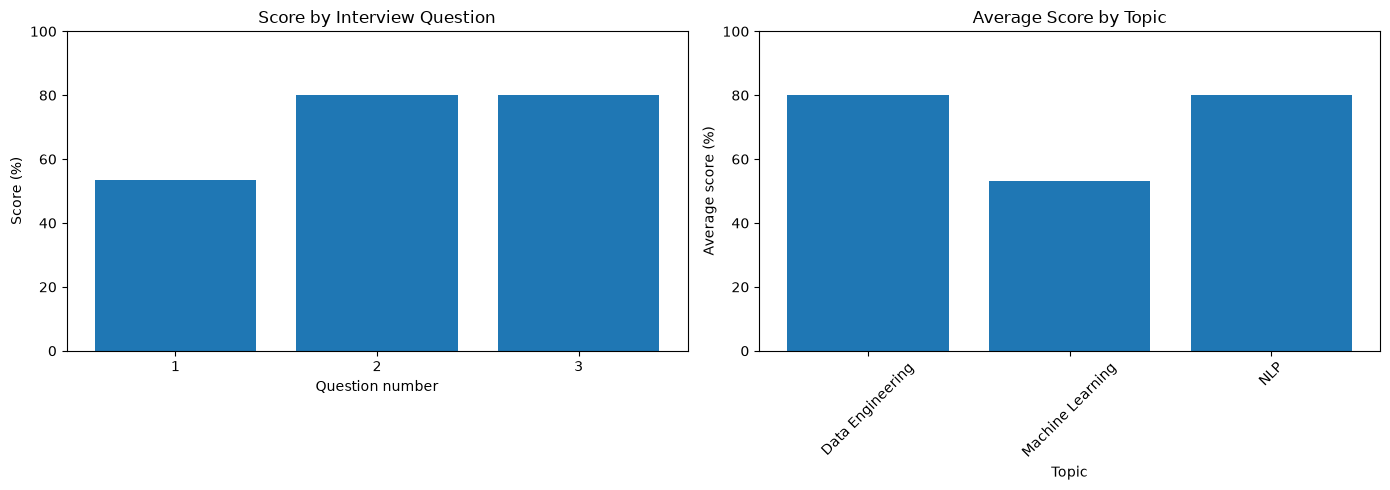

Topics to revise first: Machine Learning, Data Engineering, NLP


### Question-by-question review

,Question Number,Category,Question,Score (%),Feedback
0,1,Machine Learning,Develop a machine learning algorithm to detect...,53.33,The candidate outlines a correct high‑level pi...
1,2,Data Engineering,Create a real-time sports analytics system usi...,80.00,"The candidate provides a solid, well-structure..."
2,3,NLP,Implement a simple Retrieval-Augmented Generat...,80.00,The candidate accurately outlines the core RAG...


In [34]:
if "interview_results" not in globals() or interview_results.empty:
    print("Run the mock interview cell first.")
else:
    avg_score = interview_results["Score (%)"].mean()
    avg_technical = interview_results["Technical Accuracy (0-5)"].mean()
    avg_completeness = interview_results["Completeness (0-5)"].mean()
    avg_communication = interview_results["Communication Clarity (0-5)"].mean()

    print("INTERVIEW PERFORMANCE SUMMARY")
    print("-" * 45)
    print(f"Overall average: {avg_score:.1f}%")
    print(f"Technical accuracy: {avg_technical:.2f}/5")
    print(f"Completeness: {avg_completeness:.2f}/5")
    print(f"Communication clarity: {avg_communication:.2f}/5")

    category_scores = interview_results.groupby("Category", dropna=False).agg(
        Questions=("Question", "count"),
        Average_Score_Percent=("Score (%)", "mean"),
        Average_Technical_Accuracy=("Technical Accuracy (0-5)", "mean"),
        Average_Completeness=("Completeness (0-5)", "mean"),
        Average_Communication=("Communication Clarity (0-5)", "mean"),
    ).reset_index()
    category_scores["Average_Score_Percent"] = category_scores["Average_Score_Percent"].round(1)
    display(category_scores.sort_values("Average_Score_Percent"))

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].bar(interview_results["Question Number"].astype(str), interview_results["Score (%)"])
    axes[0].set_title("Score by Interview Question")
    axes[0].set_xlabel("Question number")
    axes[0].set_ylabel("Score (%)")
    axes[0].set_ylim(0, 100)

    axes[1].bar(category_scores["Category"].astype(str), category_scores["Average_Score_Percent"])
    axes[1].set_title("Average Score by Topic")
    axes[1].set_xlabel("Topic")
    axes[1].set_ylabel("Average score (%)")
    axes[1].tick_params(axis="x", rotation=45)
    axes[1].set_ylim(0, 100)
    plt.tight_layout()
    plt.show()

    weak_topics = category_scores.sort_values("Average_Score_Percent").head(3)["Category"].astype(str).tolist()
    print("Topics to revise first:", ", ".join(weak_topics))

    display(Markdown("### Question-by-question review"))
    display(interview_results[["Question Number", "Category", "Question", "Score (%)", "Feedback"]])

## 10. Generate personalized revision exercises with Groq

The agent uses your lowest-scoring topics and interview feedback to prepare a compact revision plan and practice questions.

In [35]:
if "interview_results" not in globals() or interview_results.empty:
    print("Run the mock interview and performance-analysis cells first.")
else:
    weak_topics = (category_scores.sort_values("Average_Score_Percent").head(3)["Category"].astype(str).tolist()
                   if "category_scores" in globals() and not category_scores.empty else [])
    review_records = interview_results.sort_values("Score (%)").head(3)[["Question", "Category", "Score (%)", "Feedback", "Improvements"]].to_dict(orient="records")
    prompt = f"""Create a practical revision plan for a candidate preparing for {interview_results['Target Role'].iloc[0]}.
Weak topics: {weak_topics}
Lowest-scoring answers and feedback: {json.dumps(review_records, ensure_ascii=False)}
Return concise Markdown with:
1. Three prioritized revision actions.
2. Three short practice exercises, each with a question and what a good answer should cover.
3. A 5-day revision plan with one task per day.
Do not claim the candidate has skills that were not demonstrated. Keep tasks feasible for a student."""
    try:
        revision_plan = groq_chat([
            {"role": "system", "content": "You are a supportive technical interview coach. Give actionable, realistic revision steps based on evidence."},
            {"role": "user", "content": prompt},
        ], temperature=0.3, max_completion_tokens=1400)
        display(Markdown(revision_plan))
    except Exception as exc:
        print("Could not generate the revision plan. Check Groq setup and rerun this cell.")
        print(str(exc)[:500])

## 1. Prioritized Revision Actions  

| # | Focus Area | Concrete Action | Why It Matters |
|---|------------|-----------------|----------------|
| 1 | **Fake‑news ML pipeline** | • Write a detailed, step‑by‑step design that includes **tokenization, embeddings (e.g., BERT, TF‑IDF), feature engineering, dimensionality reduction, model choice (SVM, logistic regression, transformer‑based), cross‑validation, evaluation metrics (accuracy, precision, recall, F1, ROC‑AUC), bias mitigation, and explainability**. | The lowest‑scoring answer omitted many of these details. Covering them will raise the depth of your responses. |
| 2 | **Data‑engineering specifics** | • Draft a **schema diagram** and **validation rules** for sensor data. <br>• Explain **event‑time vs. processing‑time**, **windowing strategies** (tumbling, sliding, session), and how to handle late data. <br>• Show how to integrate the stream with an existing sports‑analytics API. | The feedback highlighted missing details on event‑time handling, windowing, and schema design. |
| 3 | **RAG implementation details** | • Specify the **embedding model** (`text-embedding-ada-002`), **LLM** (`gpt-3.5-turbo`), **similarity metric** (cosine), and **threshold selection**. <br>• Detail **prompt construction** and **fallback strategies** for out‑of‑distribution queries. | The answer was correct but lacked concrete implementation specifics. |

---

## 2. Short Practice Exercises  

| # | Question | What a Good Answer Should Cover |
|---|----------|---------------------------------|
| 1 | *Design a fake‑news detection system for Twitter. Include data sources, preprocessing, feature extraction, model choice, evaluation, and bias mitigation.* | • Twitter API ingestion, tweet cleaning, tokenization, embeddings (BERT/TF‑IDF). <br>• Feature engineering (n‑grams, sentiment, metadata). <br>• Model selection (logistic regression vs. fine‑tuned BERT). <br>• Cross‑validation, metrics (F1, ROC‑AUC). <br>• Bias checks (gender, political slant), explainability (SHAP). |
| 2 | *Outline a real‑time sports‑analytics pipeline that ingests sensor data from a football match. Explain event‑time handling, windowing, and how you would store and expose the results.* | • Kafka/Flink ingestion, event‑time timestamps, watermarking. <br>• Tumbling vs. sliding windows (e.g., 5‑second windows for speed). <br>• Schema design (player ID, timestamp, metrics). <br>• Storage (Kafka topics, ClickHouse). <br>• API endpoint or dashboard for live stats. |
| 3 | *Implement a minimal RAG pipeline in Python using OpenAI embeddings and FAISS. Show how you would detect out‑of‑distribution queries and handle them.* | • Load `text-embedding-ada-002`, compute embeddings, build FAISS index. <br>• Query: embed, search top‑k, compute cosine similarity, apply threshold. <br>• Prompt construction with retrieved passages. <br>• OOD handling: if similarity < threshold → safe completion or clarification request. |

---

## 3. 5‑Day Revision Plan  

| Day | Task | Resources / Tips |
|-----|------|------------------|
| **Day 1** | **Deep‑Dive NLP for Fake‑News** <br>• Read the HuggingFace “Fine‑tune a BERT model” tutorial. <br>• Sketch a full pipeline diagram (data → preprocessing → embeddings → features → model → evaluation). | HuggingFace docs, scikit‑learn feature extraction guide. |
| **Day 2** | **Build & Evaluate a Fake‑News Classifier** <br>• Use the `FakeNewsNet` dataset. <br>• Train a logistic regression on TF‑IDF + a BERT fine‑tuned model. <br>• Report accuracy, precision, recall, F1, ROC‑AUC. | Kaggle “Fake News Detection” notebooks, scikit‑learn metrics. |
| **Day 3** | **Stream‑Processing Fundamentals** <br>• Study event‑time vs. processing‑time in Flink. <br>• Implement a simple Flink job that reads synthetic sensor data, applies tumbling windows, and writes to a sink. | Apache Flink documentation, “Event Time Processing” tutorial. |
| **Day 4** | **Integrate Schema & Validation** <br>• Define a JSON schema for sensor events. <br>• Add schema validation in the Flink job. <br>• Show how to expose results via a REST endpoint (e.g., FastAPI). | JSON Schema spec, FastAPI docs. |
| **Day 5** | **RAG + OOD Detection** <br>• Write a Python script that: <br>   1. Loads `text-embedding-ada-002`

## 11. Export interview results

This exports the candidate's answers, scores, feedback, and suggested answers to a CSV file for the lab report. Keep this file private if it contains personal information.

In [36]:
from pathlib import Path
from IPython.display import display, FileLink

if "interview_results" in globals() and not interview_results.empty:
    OUTPUT_CSV = Path("interview_performance_results.csv")

    interview_results.to_csv(
        OUTPUT_CSV,
        index=False,
        encoding="utf-8-sig"
    )

    print(f"Saved: {OUTPUT_CSV.resolve()}")
    display(FileLink(str(OUTPUT_CSV)))

else:
    print("No interview results found. Complete the mock interview first.")

Saved: C:\Users\SAKSHI\Downloads\bdsma\interview_performance_results.csv


C:\Users\SAKSHI\Downloads\bdsma\interview_performance_results.csv

## Expected output and conclusion

After running the notebook, you should have:
- dataset cleaning statistics and category/difficulty charts;
- a keyword-frequency table/chart;
- role-tailored questions generated with Groq and questions drawn from the uploaded dataset;
- scores and feedback for each mock interview answer;
- topic-wise performance and weak-topic identification;
- an AI-generated revision plan and downloadable results CSV.

**Conclusion template:** The experiment combines text analytics over a software interview question dataset with a Groq-powered interview assistant. It performs basic data cleaning, explores topic and difficulty distributions, generates role-focused questions, evaluates candidate responses using a rubric, and summarizes performance to recommend revision areas. Its key limitations are the relatively small static dataset, heuristic role-to-category matching, and variability in LLM-based scoring; therefore, results should be treated as practice feedback rather than an objective hiring decision.

### Troubleshooting
- **Secret error:** Add `GROQ_API_KEY` in Colab Secrets and enable notebook access.
- **Model not found / access error:** Set `MODEL` in the setup cell to a model ID available to your Groq account.
- **Column error:** Check the CSV column names printed in Section 2. The file must contain a question column; an answer column is recommended.
- **No matching role categories:** The notebook automatically falls back to the full dataset.
- **Rate limit / API error:** Try fewer questions and rerun the relevant cell after checking your Groq account's limits.